# YOLO26n Vietnamese Vehicle Detection (Kaggle)

Trains `yolo26n` on four classes (bus, car, motorcycle, truck), then validates, evaluates on the test split, visualizes and packages the results. Run the cells top to bottom: later cells reuse variables defined by earlier ones.

Expected dataset layout under the Kaggle input; class names are read from `data.yaml`:

```
<dataset-root>/data.yaml
<dataset-root>/images/{train,val,test}
<dataset-root>/labels/{train,val,test}
```

In [1]:
# ==============================================================================
# CELL 0: Install Dependencies and Common Imports
# ==============================================================================
import subprocess
import sys


def install_package(package, version=None):
    """Install a package with an optional pinned version."""
    package_spec = f"{package}=={version}" if version else package
    subprocess.check_call([sys.executable, "-m", "pip", "install", package_spec, "-q"])


install_package("ultralytics", "8.4.174")

# Imported after the install so the pinned ultralytics is the one loaded.
import json
import os
import time
import zipfile
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime
from pathlib import Path
from shutil import copy2, rmtree

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import FileLink, display
from ultralytics import YOLO



Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
# ==============================================================================
# CELL 1: Training Configuration
# ==============================================================================
# optimizer="auto" picks MuSGD or AdamW by iteration count and ignores lr0, momentum and warmup_bias_lr.
TRAINING_CONFIG = {
    "model": "yolo26n.pt",
    "epochs": 50,  # ~30 optimizer steps per epoch at this dataset size
    "patience": 5,
    "batch": 8,
    #"imgsz": 640,
    #"optimizer": "auto",
    "lrf": 0.01,
    "weight_decay": 0.0005,
    "warmup_epochs": 3.0,
    "warmup_momentum": 0.8,
    #"box": 7.5,
    #"cls": 0.5,
    #"dfl": 1.5,
    "hsv_h": 0.015,
    "hsv_s": 0.5,
    "hsv_v": 0.3,
    "degrees": 0.0,
    "translate": 0.1,
    "scale": 0.3,
    "shear": 0.0,
    "perspective": 0.0,
    "flipud": 0.0,
    "fliplr": 0.5,
    "mosaic": 1.0,
    "mixup": 0.1,
    "close_mosaic": 10,
    "amp": True,
    "cache": False,  # the 640x640 training set is ~2 GB per process
    # Fraction of imgsz (0.25 -> 0.75x-1.25x); a bool True is read as 1.0 (+/-100%).
    "multi_scale": 0.25,
    "cos_lr": True,
    # Must be absolute: Ultralytics nests a relative project under runs/<task>/.
    "project": "/kaggle/working/runs/train",
    "name": "YOLO26n_vehicle_detection",
    "exist_ok": True,
    "plots": True,
    "seed": 0,
    "deterministic": True,
    "workers": 2,
}

In [ ]:
# ============================================================================
# CELL 2: Copy Train, Validation and Test Splits, Resolve, and Validate Dataset
# ============================================================================
DATASET_ROOT = Path("/kaggle/input/datasets/keyshiftf/vehicle-danang-2025/merged_dataset")
WORKING_DATASET_ROOT = Path("/kaggle/working/vehicle-danang-2025/merged_dataset")

# Layout: <root>/images/{train,val,test}, <root>/labels/{train,val,test} and <root>/data.yaml.
required_paths = [DATASET_ROOT / "data.yaml"] + [
    DATASET_ROOT / kind / split for split in ("train", "val") for kind in ("images", "labels")
]
missing_paths = [str(path) for path in required_paths if not path.exists()]

if missing_paths:
    contents = []
    if DATASET_ROOT.exists():
        contents = sorted(item.name for item in DATASET_ROOT.iterdir())
    raise FileNotFoundError(
        "Kaggle dataset does not contain the required YOLO files.\n"
        "Missing:\n  - "
        + "\n  - ".join(missing_paths)
        + "\nDataset mount contents: "
        + ", ".join(contents)
    )

# Copy the train, validation and test images and labels to the writable working directory.
train_images_dir = WORKING_DATASET_ROOT / "images" / "train"
train_labels_dir = WORKING_DATASET_ROOT / "labels" / "train"
val_images_dir = WORKING_DATASET_ROOT / "images" / "val"
val_labels_dir = WORKING_DATASET_ROOT / "labels" / "val"
test_images_dir = WORKING_DATASET_ROOT / "images" / "test"
test_labels_dir = WORKING_DATASET_ROOT / "labels" / "test"
# The test split is optional in the input dataset.
has_test_split = all((DATASET_ROOT / kind / "test").is_dir() for kind in ("images", "labels"))
if WORKING_DATASET_ROOT.exists():
    rmtree(WORKING_DATASET_ROOT)

def copy_directory_with_progress(source_dir: Path, destination_dir: Path, log_interval: float = 10.0, workers: int = 32) -> None:
    """Copy a directory with a thread pool, printing a plain-text progress line every `log_interval` seconds."""
    name = f"{source_dir.parent.name}/{source_dir.name}"
    files = [path for path in source_dir.rglob("*") if path.is_file()]
    total_bytes = sum(path.stat().st_size for path in files)
    destination_dir.mkdir(parents=True, exist_ok=True)
    # Create every target folder up front so the worker threads never race on mkdir.
    for folder in {source_file.relative_to(source_dir).parent for source_file in files}:
        (destination_dir / folder).mkdir(parents=True, exist_ok=True)
    print(f"[COPY] {name}: {len(files)} files, {total_bytes / 1024**2:.1f} MB, {workers} threads", flush=True)

    def copy_one(source_file: Path) -> int:
        copy2(source_file, destination_dir / source_file.relative_to(source_dir))
        return source_file.stat().st_size

    copied_bytes = 0
    start = last_log = time.time()
    with ThreadPoolExecutor(max_workers=workers) as executor:
        # map() yields in order and re-raises any copy error here, in the main thread.
        for count, size in enumerate(executor.map(copy_one, files), start=1):
            copied_bytes += size
            if time.time() - last_log >= log_interval:
                last_log = time.time()
                print(
                    f"[COPY] {name}: {count}/{len(files)} files ({count / len(files):.0%}), "
                    f"{copied_bytes / 1024**2:.1f}/{total_bytes / 1024**2:.1f} MB, {last_log - start:.0f}s".ljust(100),
                    end="\r",
                    flush=True,
                )
    # ljust overwrites the leftover characters of the last progress line.
    print(f"[COPY] {name}: done, {len(files)} files in {time.time() - start:.0f}s".ljust(100), flush=True)

copy_directory_with_progress(DATASET_ROOT / "images" / "train", train_images_dir)
copy_directory_with_progress(DATASET_ROOT / "labels" / "train", train_labels_dir)
copy_directory_with_progress(DATASET_ROOT / "images" / "val", val_images_dir)
copy_directory_with_progress(DATASET_ROOT / "labels" / "val", val_labels_dir)
if has_test_split:
    copy_directory_with_progress(DATASET_ROOT / "images" / "test", test_images_dir)
    copy_directory_with_progress(DATASET_ROOT / "labels" / "test", test_labels_dir)

# Build a writable training YAML that preserves the input dataset's class names.
with open(DATASET_ROOT / "data.yaml", encoding="utf-8") as file:
    input_data_config = yaml.safe_load(file)
source_names = input_data_config["names"]
if isinstance(source_names, list):
    source_names = dict(enumerate(source_names))
UNIFIED_CLASSES = {int(index): name for index, name in source_names.items()}

data_yaml = "/kaggle/working/vehicle_danang.yaml"
data_config = {
    "train": str(train_images_dir),
    "val": str(val_images_dir),
    "names": input_data_config["names"],
}
if has_test_split:
    data_config["test"] = str(test_images_dir)
with open(data_yaml, "w", encoding="utf-8") as file:
    yaml.safe_dump(data_config, file, sort_keys=False, allow_unicode=True)

train_images = len(list(train_images_dir.glob("*")))
val_images = len(list(val_images_dir.glob("*")))
test_images = len(list(test_images_dir.glob("*")))
train_labels = len(list(train_labels_dir.glob("*.txt")))
val_labels = len(list(val_labels_dir.glob("*.txt")))
test_labels = len(list(test_labels_dir.glob("*.txt")))
print("[INFO] Dataset copied and validated")
print(f"  Input dataset root: {DATASET_ROOT}")
print(f"  Working root (train/val/test): {WORKING_DATASET_ROOT}")
print(f"  Classes: {UNIFIED_CLASSES}")
print(f"  Train images / labels: {train_images} / {train_labels}")
print(f"  Validation images / labels: {val_images} / {val_labels}")
print(f"  Test images / labels: {test_images} / {test_labels}")
print(f"  Training YAML: {data_yaml}")
print(
    "  YAML paths: "
    + ", ".join(f"{key}={data_config.get(key)}" for key in ("train", "val", "test"))
)


Copying images/train:   0%|          | 0/20438 [00:00<?, ?file/s]

Copying labels/train:   0%|          | 0/20438 [00:00<?, ?file/s]

Copying images/val:   0%|          | 0/5839 [00:00<?, ?file/s]

Copying labels/val:   0%|          | 0/5839 [00:00<?, ?file/s]

[INFO] Dataset copied and validated
  Input dataset root: /kaggle/input/datasets/keyshiftf/vehicle-danang-2025/merged_dataset
  Working train/validation root: /kaggle/working/vehicle-danang-2025/merged_dataset
  Classes: {0: 'car', 1: 'motorbike', 2: 'bus', 3: 'truck'}
  Train images / labels: 20438 / 20438
  Validation images / labels: 5839 / 5839
  Test images / labels: 2921 / 2921
  Training YAML: /kaggle/working/vehicle_danang.yaml
  YAML paths: train=/kaggle/working/vehicle-danang-2025/merged_dataset/images/train, val=/kaggle/working/vehicle-danang-2025/merged_dataset/images/val, test=/kaggle/input/datasets/keyshiftf/vehicle-danang-2025/merged_dataset/images/test


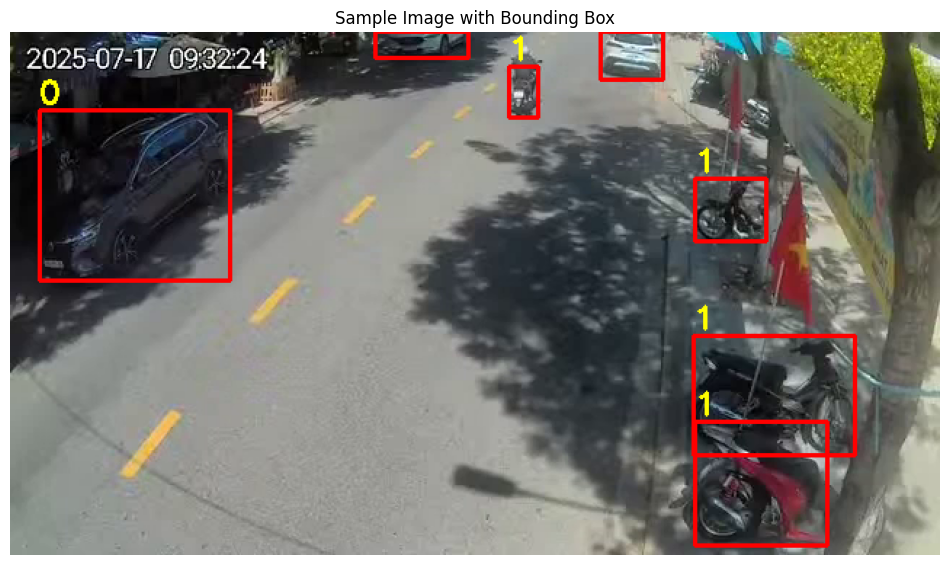

In [ ]:
# ============================================================================
# CELL 3: Sample Image with Bounding Box
# ============================================================================
image_path = str(next(iter(sorted(train_images_dir.glob("*"))), ""))
image = cv2.imread(image_path)
if image is not None:
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w, _ = image.shape
    label_path = str(train_labels_dir / (Path(image_path).stem + ".txt"))

    if os.path.exists(label_path):
        with open(label_path, "r") as f:
            lines = f.readlines()

        for line in lines:
            parts = line.strip().split()
            if len(parts) == 5:
                cls, x_center, y_center, bw, bh = map(float, parts)
                cls = int(cls)
                x1 = int((x_center - bw / 2) * w)
                y1 = int((y_center - bh / 2) * h)
                x2 = int((x_center + bw / 2) * w)
                y2 = int((y_center + bh / 2) * h)
                cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)
                cv2.putText(image, str(cls), (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 0), 2)

        plt.figure(figsize=(12, 8))
        plt.imshow(image)
        plt.title("Sample Image with Bounding Box")
        plt.axis("off")
        plt.show()
    else:
        print(f"Cannot find label file: {label_path}")
else:
    print(f"Cannot read image: {image_path}")

In [ ]:
# ==============================================================================
# CELL 4: GPU Verification
# ==============================================================================
def select_device():
    """Use two GPUs when available, otherwise use one GPU or CPU."""
    device_count = torch.cuda.device_count() if torch.cuda.is_available() else 0
    if device_count >= 2:
        return [0, 1]
    if device_count == 1:
        return 0
    return "cpu"


device = select_device()
print(f"[INFO] CUDA available: {torch.cuda.is_available()}")
print(f"[INFO] Device count: {torch.cuda.device_count()}")
print(f"[INFO] Training device: {device}")



[INFO] CUDA available: True
[INFO] Device count: 2
[INFO] Training device: [0, 1]


In [ ]:
# ==============================================================================
# CELL 5: Training Execution
# ==============================================================================
def run_training(config: dict, data_yaml: str, device):
    """Train the configured YOLO detector."""
    model = YOLO(config["model"])
    train_args = {key: value for key, value in config.items() if key != "model"}
    print(f"[INFO] Starting training at {datetime.now():%Y-%m-%d %H:%M:%S}")
    return model.train(data=data_yaml, device=device, **train_args)


training_results = run_training(TRAINING_CONFIG, data_yaml, device)



[INFO] Starting training at 2026-10-26 18:32:05
New https://pypi.org/project/ultralytics/8.4.190 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/vehicle_danang.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/50      1.18G     0.8863     0.7538   0.003541         34        640: 100% ━━━━━━━━━━━━ 2555/2555 6.5it/s 6:32
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 365/365 11.3it/s 32.3s
                   all       5839      48482      0.807      0.758      0.811      0.651

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/50      1.18G     0.9108     0.6725   0.003672         11        672: 100% ━━━━━━━━━━━━ 2555/2555 6.6it/s 6:28
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 365/365 10.9it/s 33.6s
                   all       5839      48482      0.825      0.732      0.816      0.659

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/50      1.18G     0.9162     0.6395   0.003727         43        800: 100%

In [ ]:
# ==============================================================================
# CELL 6: Locate Weights
# ==============================================================================
model_dir = Path(TRAINING_CONFIG["project"]) / TRAINING_CONFIG["name"]
best_weights = model_dir / "weights" / "best.pt"
last_weights = model_dir / "weights" / "last.pt"
assert best_weights.exists(), f"Training output not found: {best_weights}"

print(f"[INFO] Best weights: {best_weights}")
print(f"[INFO] Last weights: {last_weights}")
display(FileLink(os.path.relpath(best_weights)))
display(FileLink(os.path.relpath(last_weights)))


[INFO] Best weights: /kaggle/working/runs/train/vehicle_detection_v9/weights/best.pt
[INFO] Last weights: /kaggle/working/runs/train/vehicle_detection_v9/weights/last.pt


/kaggle/working/runs/train/vehicle_detection_v9/weights/best.pt

/kaggle/working/runs/train/vehicle_detection_v9/weights/last.pt


image 1/1 /kaggle/working/vehicle-danang-2025/merged_dataset/images/val/007245.png: 384x640 2 cars, 4 motorbikes, 10.2ms
Speed: 39.5ms preprocess, 10.2ms inference, 23.2ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /kaggle/working/runs/detect/predict
[INFO] Detections: 6


[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'car', 1: 'motorbike', 2: 'bus', 3: 'truck'}
 obb: None
 orig_img: array([[[190, 203, 206],
         [190, 203, 206],
         [202, 215, 218],
         ...,
         [ 87,  97,  89],
         [ 69,  71,  64],
         [ 82,  84,  77]],
 
        [[191, 204, 207],
         [194, 207, 210],
         [200, 213, 216],
         ...,
         [105, 115, 107],
         [ 68,  70,  63],
         [ 89,  91,  84]],
 
        [[193, 206, 209],
         [200, 213, 216],
         [194, 207, 210],
         ...,
         [ 62,  72,  64],
         [ 67,  69,  62],
         [ 97,  99,  92]],
 
        ...,
 
        [[ 96,  98,  91],
         [ 97,  99,  92],
         [ 96,  98,  91],
         ...,
         [ 64,  63,  73],
         [ 66,  65,  75],
         [ 66,  65,  75]],
 
        [[ 88,  90,  83],
         [ 88,  90,  83],
         [

In [ ]:
# ==============================================================================
# CELL 7: Evaluate Best Weights on Validation and Test Splits
# ==============================================================================
def evaluate_split(weights: Path, data_yaml: str, device, output_dir: Path, split: str, plots: bool = False):
    """Validate the weights on one split; returns None when the split is not in the dataset YAML."""
    with open(data_yaml, encoding="utf-8") as file:
        if split not in yaml.safe_load(file):
            print(f"[WARNING] No {split} split in the dataset YAML, evaluation skipped")
            return None
    result = YOLO(str(weights)).val(
        data=data_yaml,
        split=split,
        device=device[0] if isinstance(device, list) else device,
        project=str(output_dir),
        name=f"final_{split}",
        exist_ok=True,
        plots=plots,
        verbose=False,
    )
    per_class = {}
    for position, class_index in enumerate(result.box.ap_class_index):
        precision, recall, map50, map50_95 = result.box.class_result(position)
        per_class[result.names[int(class_index)]] = {
            "instances": int(result.nt_per_class[int(class_index)]),
            "precision": float(precision),
            "recall": float(recall),
            "mAP50": float(map50),
            "mAP50-95": float(map50_95),
        }
    return {
        "save_dir": str(result.save_dir),
        "overall": {
            "precision": float(result.box.mp),
            "recall": float(result.box.mr),
            "mAP50": float(result.box.map50),
            "mAP50-95": float(result.box.map),
        },
        "per_class": per_class,
    }


def metrics_table(split_metrics: dict) -> pd.DataFrame:
    """Per-class results plus an `all` row as a table."""
    table = pd.DataFrame(split_metrics["per_class"]).T
    table.loc["all"] = [table["instances"].sum(), *split_metrics["overall"].values()]
    table["instances"] = table["instances"].astype(int)
    return table.round(4)


# The test split is only used here, after best.pt was already selected on the validation split.
val_metrics = evaluate_split(best_weights, data_yaml, device, model_dir, "val")
test_metrics = evaluate_split(best_weights, data_yaml, device, model_dir, "test", plots=True)
for split, split_metrics in (("val", val_metrics), ("test", test_metrics)):
    if split_metrics:
        table = metrics_table(split_metrics)
        table.to_csv(f"{split}_metrics.csv")
        print(f"[INFO] {split} set results (best.pt):")
        display(table)


In [ ]:
# ==============================================================================
# CELL 8: Package Artifacts
# ==============================================================================
results_csv = model_dir / "results.csv"
metrics = {
    "model": TRAINING_CONFIG["model"],
    "dataset_root": str(DATASET_ROOT),
    "classes": list(UNIFIED_CLASSES.values()),
}
if results_csv.exists():
    dataframe = pd.read_csv(results_csv)
    dataframe.columns = dataframe.columns.str.strip()
    metrics["epochs_trained"] = len(dataframe)
    if "metrics/mAP50-95(B)" in dataframe.columns:
        best_row = dataframe.loc[dataframe["metrics/mAP50-95(B)"].idxmax()]
        metrics["mAP50"] = float(best_row.get("metrics/mAP50(B)", 0.0))
        metrics["mAP50-95"] = float(best_row["metrics/mAP50-95(B)"])
metrics["val"] = val_metrics
metrics["test"] = test_metrics

with open("training_metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)

zip_path = Path("vietnam_vehicle_detection_model.zip")
artifacts = [
    best_weights,
    last_weights,
    results_csv,
    Path("training_metrics.json"),
    Path(data_yaml),
    Path("val_metrics.csv"),
    Path("test_metrics.csv"),
]
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for artifact in artifacts:
        if artifact.exists():
            archive.write(artifact, artifact.name)
        else:
            print(f"[WARNING] Artifact not found, skipped: {artifact}")

print(f"[SUCCESS] Artifacts packaged: {zip_path}")
display(FileLink(str(zip_path)))


Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 120 layers, 2,375,616 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4731.7±703.3 MB/s, size: 360.0 KB)
val: Scanning /kaggle/working/vehicle-danang-2025/merged_dataset/labels/val.cache... 5839 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5839/5839 1.6Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 365/365 12.1it/s 30.2s
                   all       5839      48482      0.876      0.834      0.902      0.786
Speed: 0.5ms preprocess, 1.9ms inference, 0.0ms loss, 0.9ms postprocess per image
[SUCCESS] Artifacts packaged: vietnam_vehicle_detection_model.zip


/kaggle/working/vietnam_vehicle_detection_model.zip

[INFO] Dataset distribution saved to: dataset_distribution.png


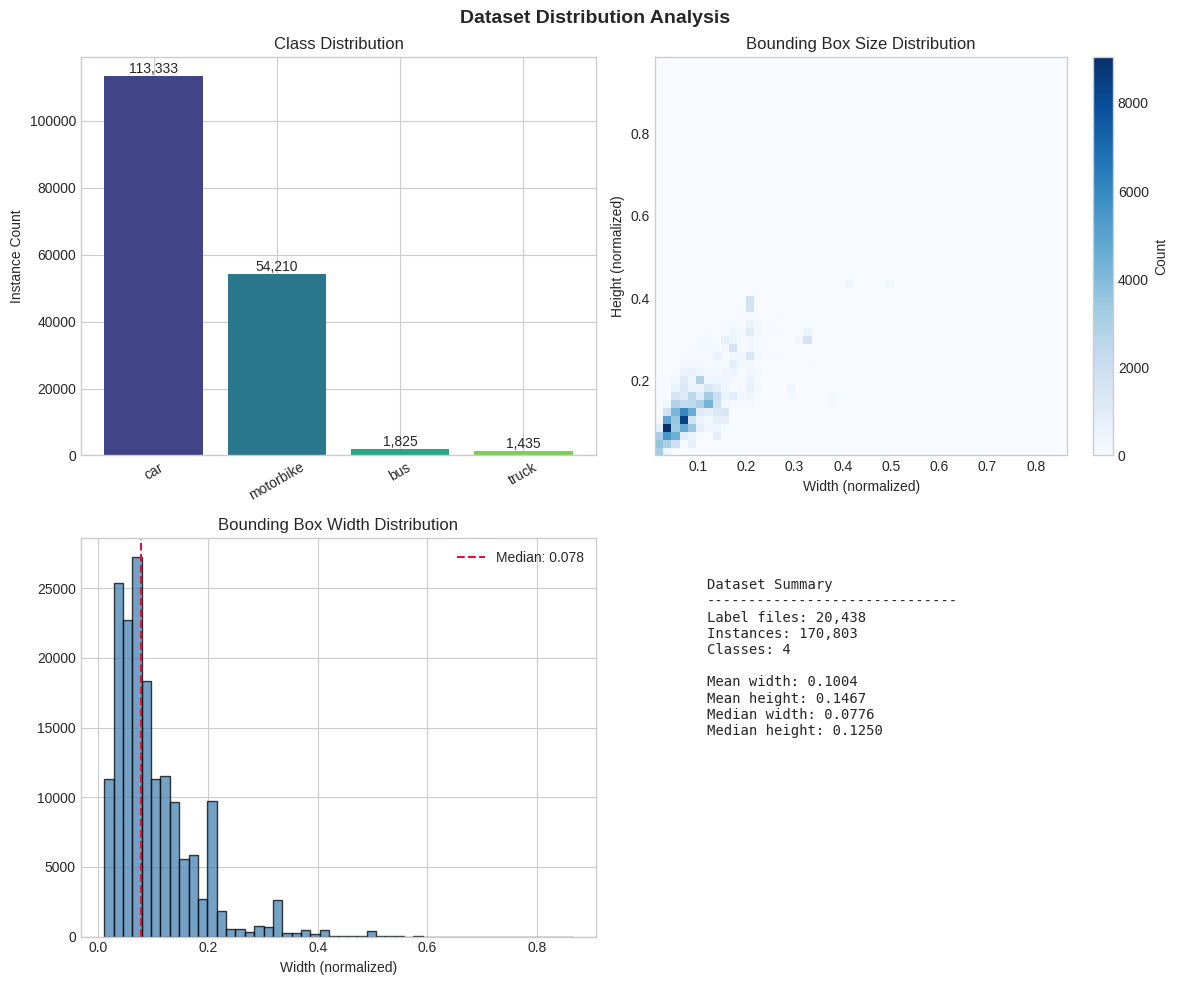

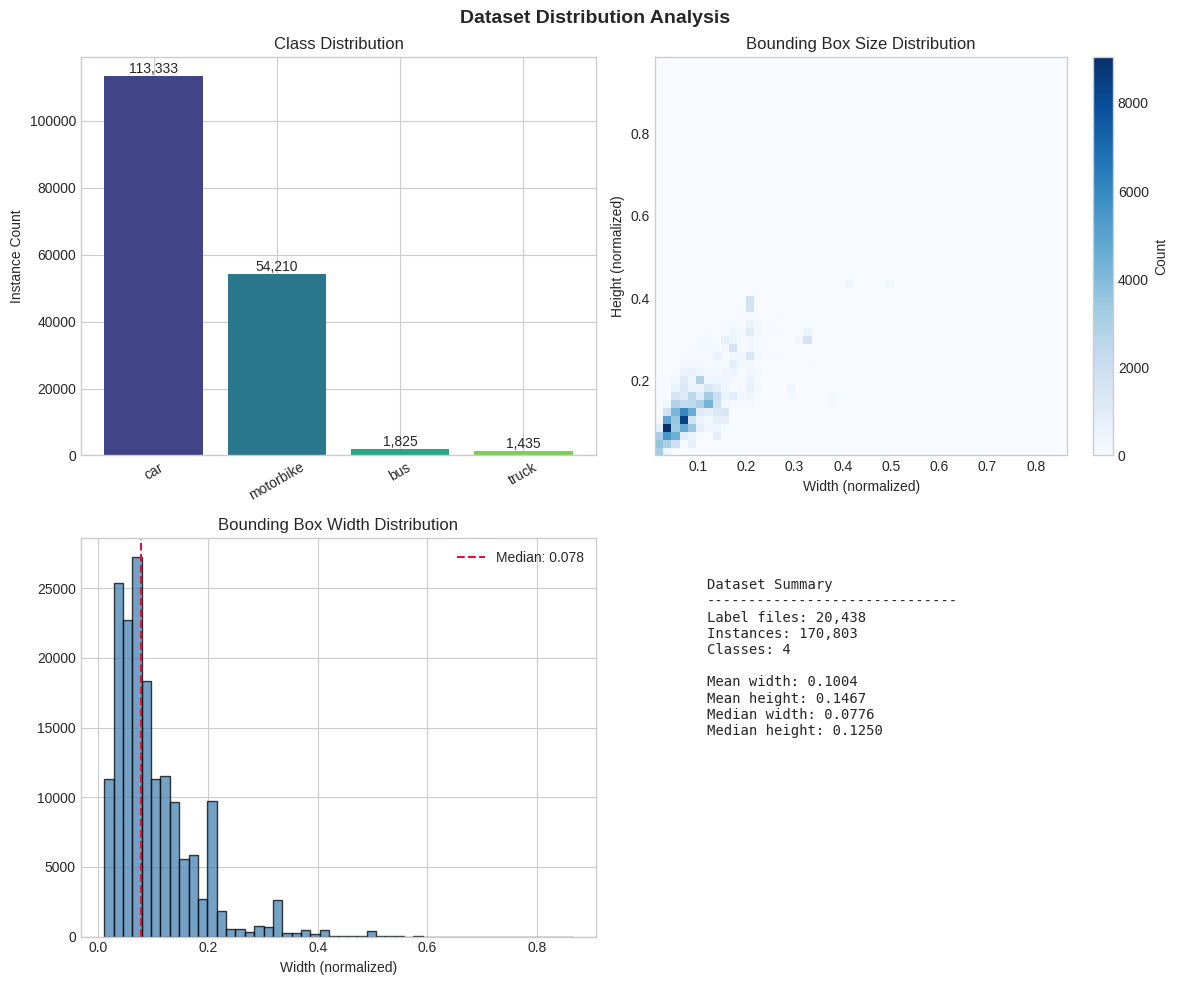

In [ ]:
# ==============================================================================
# CELL 9: Dataset Distribution Visualization
# ==============================================================================
def visualize_dataset_distribution(labels_dir: Path, class_names: dict, output_path: str = None):
    """Plot class counts and normalized bounding-box statistics."""
    class_counts = Counter()
    box_widths = []
    box_heights = []
    label_files = list(labels_dir.rglob("*.txt"))

    for label_file in label_files:
        for line in label_file.read_text(encoding="utf-8").splitlines():
            parts = line.split()
            if len(parts) < 5:
                continue
            class_index = int(parts[0])
            class_counts[class_index] += 1
            box_widths.append(float(parts[3]))
            box_heights.append(float(parts[4]))

    if not box_widths:
        print(f"[WARNING] No valid labels found in {labels_dir}")
        return None

    plt.style.use("seaborn-v0_8-whitegrid")
    figure, axes = plt.subplots(2, 2, figsize=(12, 10))
    figure.suptitle("Dataset Distribution Analysis", fontsize=14, fontweight="bold")

    class_indices = sorted(class_counts)
    class_labels = [class_names.get(index, f"class_{index}") for index in class_indices]
    counts = [class_counts[index] for index in class_indices]
    bars = axes[0, 0].bar(class_labels, counts, color=plt.cm.viridis(np.linspace(0.2, 0.8, len(counts))))
    axes[0, 0].set_title("Class Distribution")
    axes[0, 0].set_ylabel("Instance Count")
    axes[0, 0].tick_params(axis="x", rotation=30)
    for bar, count in zip(bars, counts):
        axes[0, 0].annotate(f"{count:,}", (bar.get_x() + bar.get_width() / 2, bar.get_height()), ha="center", va="bottom")

    histogram = axes[0, 1].hist2d(box_widths, box_heights, bins=50, cmap="Blues")
    figure.colorbar(histogram[3], ax=axes[0, 1], label="Count")
    axes[0, 1].set_title("Bounding Box Size Distribution")
    axes[0, 1].set_xlabel("Width (normalized)")
    axes[0, 1].set_ylabel("Height (normalized)")

    axes[1, 0].hist(box_widths, bins=50, color="steelblue", edgecolor="black", alpha=0.75)
    axes[1, 0].axvline(np.median(box_widths), color="crimson", linestyle="--", label=f"Median: {np.median(box_widths):.3f}")
    axes[1, 0].set_title("Bounding Box Width Distribution")
    axes[1, 0].set_xlabel("Width (normalized)")
    axes[1, 0].legend()

    axes[1, 1].axis("off")
    summary = (
        f"Dataset Summary\n{'-' * 30}\n"
        f"Label files: {len(label_files):,}\n"
        f"Instances: {sum(counts):,}\n"
        f"Classes: {len(class_counts)}\n\n"
        f"Mean width: {np.mean(box_widths):.4f}\n"
        f"Mean height: {np.mean(box_heights):.4f}\n"
        f"Median width: {np.median(box_widths):.4f}\n"
        f"Median height: {np.median(box_heights):.4f}"
    )
    axes[1, 1].text(0.1, 0.9, summary, transform=axes[1, 1].transAxes, family="monospace", va="top")

    figure.tight_layout()
    if output_path:
        figure.savefig(output_path, bbox_inches="tight", dpi=150)
        print(f"[INFO] Dataset distribution saved to: {output_path}")
    plt.show()
    return figure


visualize_dataset_distribution(train_labels_dir, UNIFIED_CLASSES, "dataset_distribution.png")



[INFO] Training curves saved to: training_curves.png


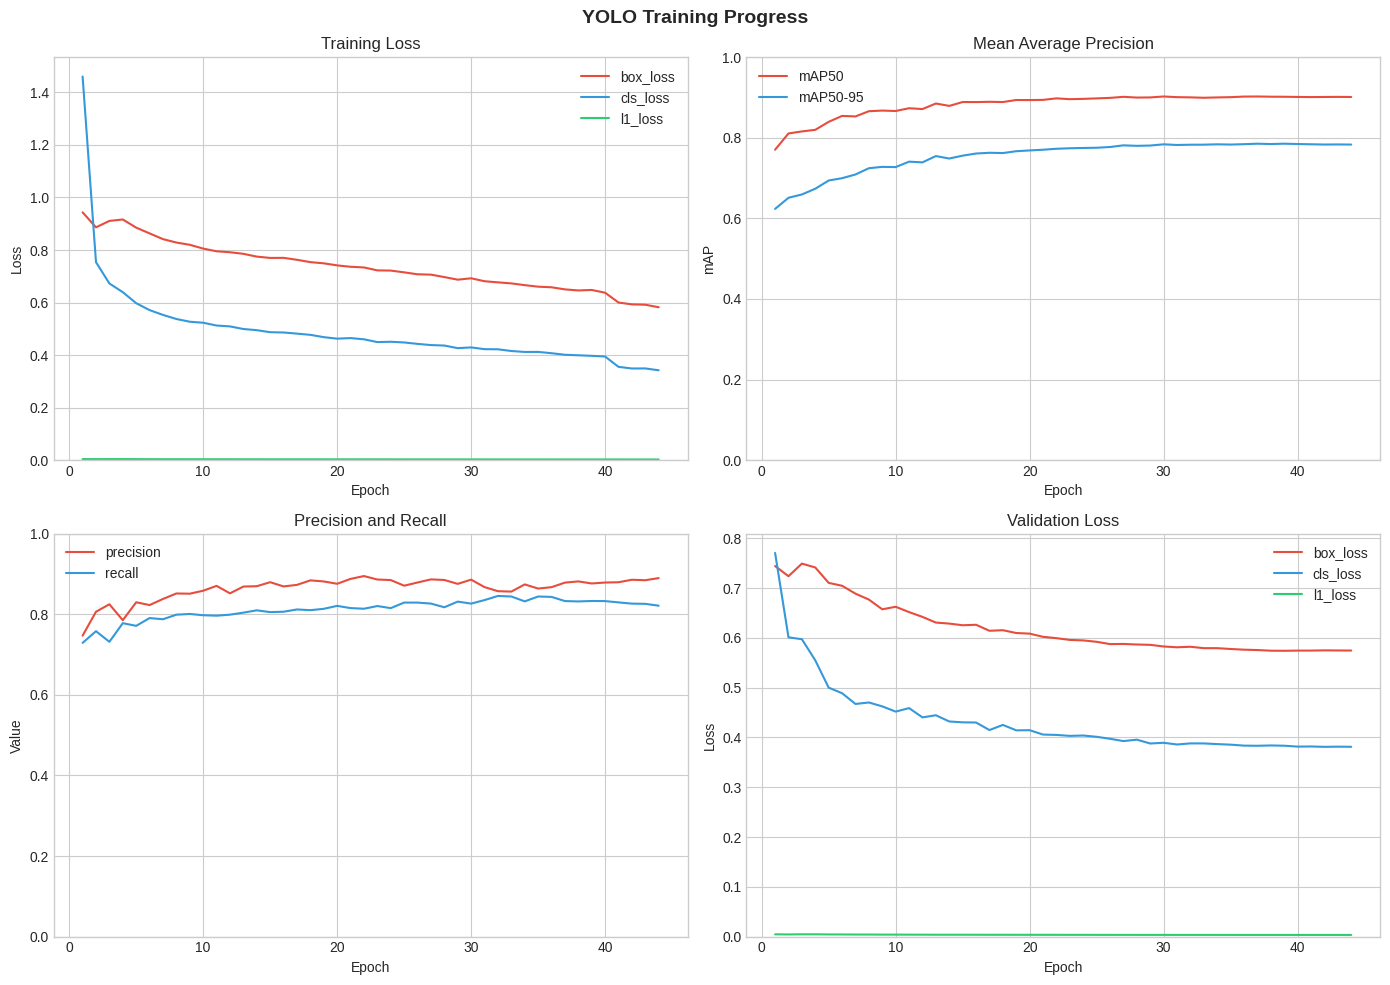

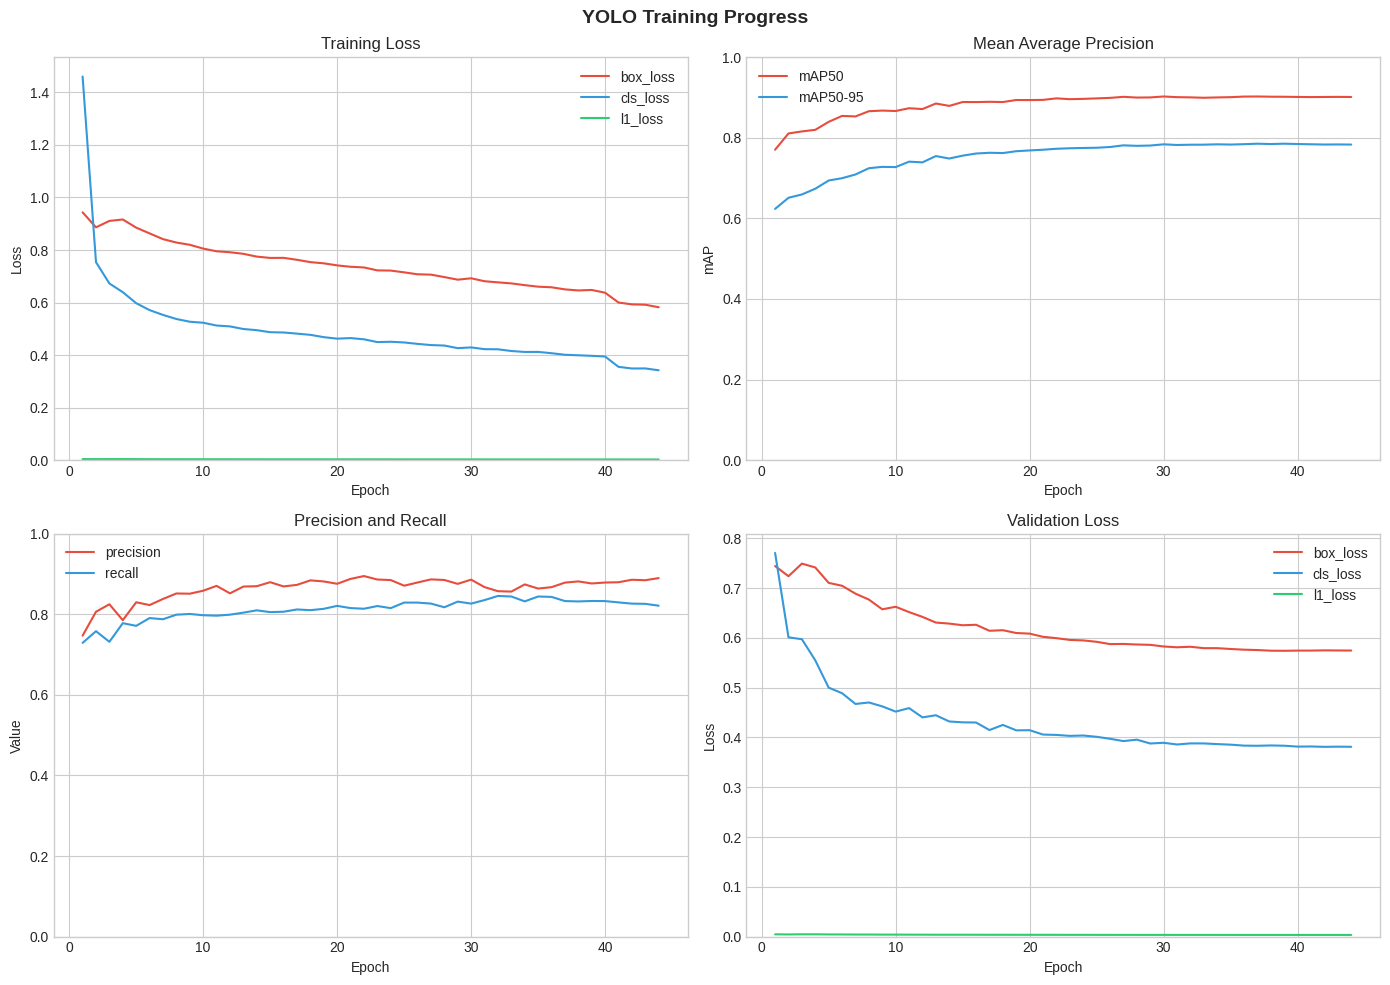

In [ ]:
# ==============================================================================
# CELL 10: Training Curves Visualization
# ==============================================================================
def visualize_training_curves(results_csv_path: Path, output_path: str = None):
    """Plot losses, detection metrics, and validation losses from results.csv."""
    if not results_csv_path.exists():
        print(f"[WARNING] Results file not found: {results_csv_path}")
        return None

    dataframe = pd.read_csv(results_csv_path)
    dataframe.columns = dataframe.columns.str.strip()
    epochs = dataframe["epoch"] if "epoch" in dataframe.columns else range(len(dataframe))
    figure, axes = plt.subplots(2, 2, figsize=(14, 10))
    figure.suptitle("YOLO Training Progress", fontsize=14, fontweight="bold")

    # YOLO26 has no DFL branch; its third loss column is l1_loss.
    plots = [
        (axes[0, 0], ["train/box_loss", "train/cls_loss", "train/l1_loss"], "Training Loss", "Loss"),
        (axes[0, 1], ["metrics/mAP50(B)", "metrics/mAP50-95(B)"], "Mean Average Precision", "mAP"),
        (axes[1, 0], ["metrics/precision(B)", "metrics/recall(B)"], "Precision and Recall", "Value"),
        (axes[1, 1], ["val/box_loss", "val/cls_loss", "val/l1_loss"], "Validation Loss", "Loss"),
    ]
    colors = ["#e74c3c", "#3498db", "#2ecc71"]
    for axis, columns, title, ylabel in plots:
        for index, column in enumerate(columns):
            if column not in dataframe.columns:
                print(f"[WARNING] Column missing from results.csv: {column}")
                continue
            axis.plot(epochs, dataframe[column], label=column.split("/")[-1].replace("(B)", ""), color=colors[index], linewidth=1.5)
        axis.set_title(title)
        axis.set_xlabel("Epoch")
        axis.set_ylabel(ylabel)
        axis.legend()
        if ylabel == "mAP" or title == "Precision and Recall":
            axis.set_ylim(0, 1)
        else:
            axis.set_ylim(bottom=0)

    figure.tight_layout()
    if output_path:
        figure.savefig(output_path, bbox_inches="tight", dpi=150)
        print(f"[INFO] Training curves saved to: {output_path}")
    plt.show()
    return figure


visualize_training_curves(results_csv, "training_curves.png")



[INFO] Confusion matrices saved to: confusion_matrices.png


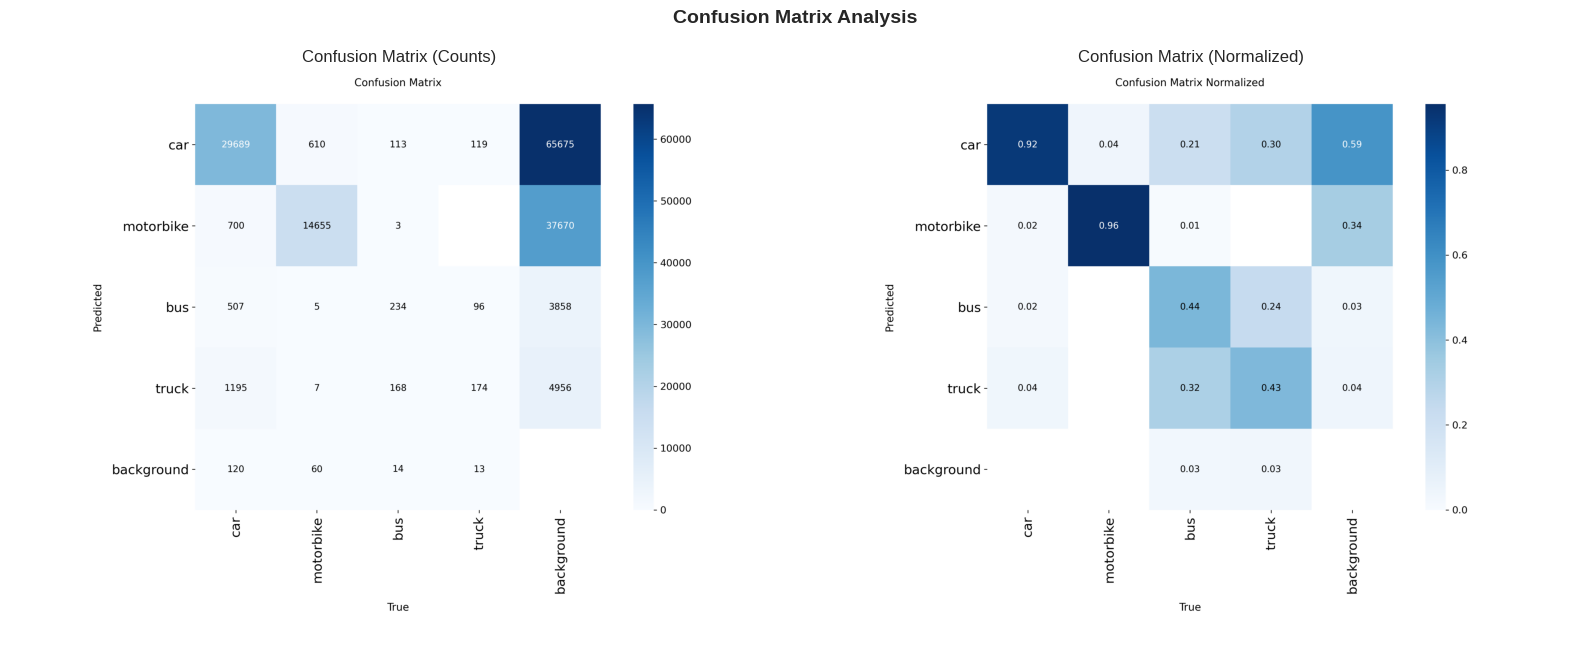

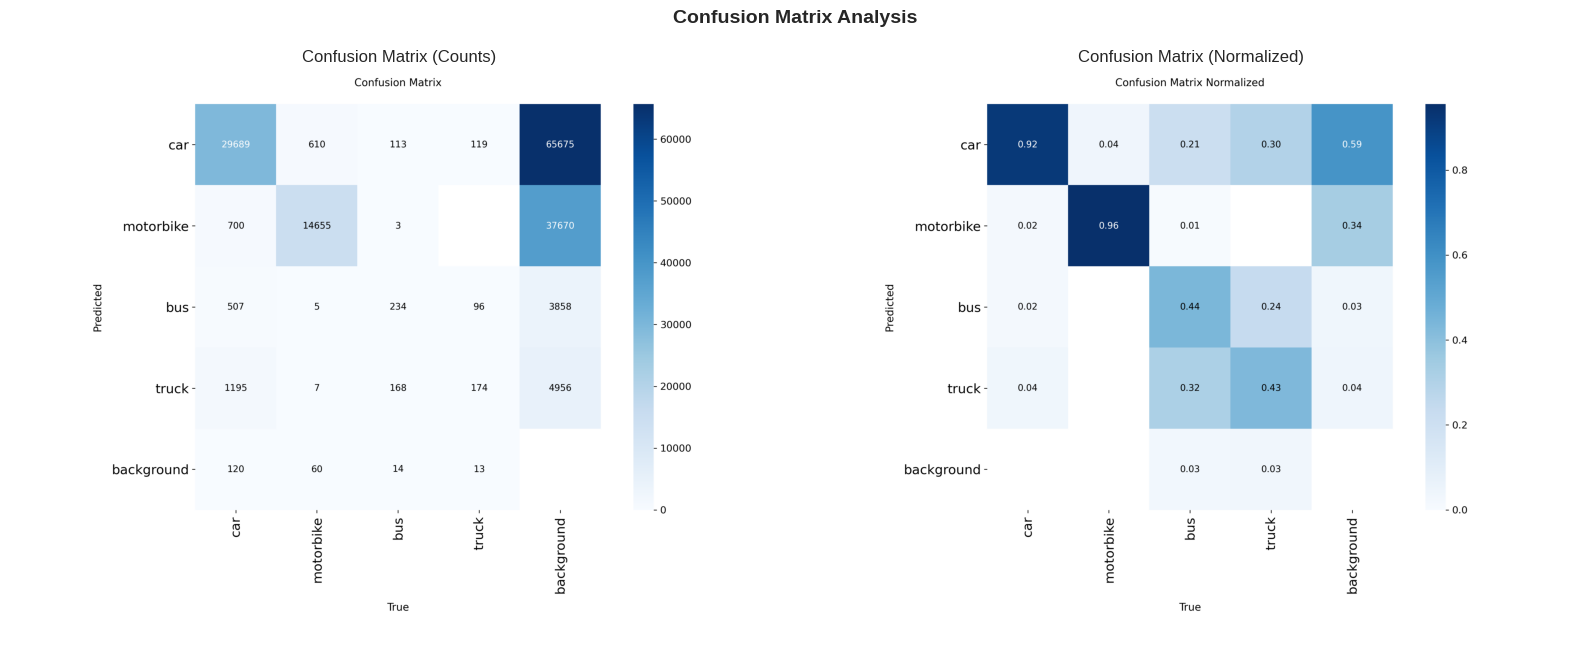

In [ ]:
# ==============================================================================
# CELL 11: Confusion Matrix Visualization
# ==============================================================================
def display_confusion_matrix(training_dir: Path, output_path: str = "confusion_matrices.png", title: str = "Confusion Matrix Analysis"):
    """Display the count and normalized confusion matrices produced by Ultralytics."""
    matrix_paths = [
        training_dir / "confusion_matrix.png",
        training_dir / "confusion_matrix_normalized.png",
    ]
    titles = ["Confusion Matrix (Counts)", "Confusion Matrix (Normalized)"]
    figure, axes = plt.subplots(1, 2, figsize=(16, 7))
    figure.suptitle(title, fontsize=14, fontweight="bold")

    for axis, matrix_path, matrix_title in zip(axes, matrix_paths, titles):
        if matrix_path.exists():
            axis.imshow(plt.imread(matrix_path))
        else:
            axis.text(0.5, 0.5, "Not Available", ha="center", va="center")
        axis.set_title(matrix_title)
        axis.axis("off")

    figure.tight_layout()
    figure.savefig(output_path, bbox_inches="tight", dpi=150)
    print(f"[INFO] Confusion matrices saved to: {output_path}")
    plt.show()
    return figure


display_confusion_matrix(model_dir)
if test_metrics:
    display_confusion_matrix(
        Path(test_metrics["save_dir"]),
        output_path="confusion_matrices_test.png",
        title="Confusion Matrix Analysis (Test Set)",
    )



In [ ]:
# ==============================================================================
# CELL 12: Validation vs Test Comparison
# ==============================================================================
def plot_val_test_comparison(val_result: dict, test_result: dict, output_path: str = None):
    """Grouped bars comparing validation and test results for every metric, per class and overall."""
    tables = {"Validation": metrics_table(val_result), "Test": metrics_table(test_result)}
    colors = {"Validation": "#3498db", "Test": "#e67e22"}
    labels = list(tables["Validation"].index)
    positions = np.arange(len(labels))
    width = 0.38

    figure, axes = plt.subplots(2, 2, figsize=(14, 9))
    figure.suptitle("Validation vs Test Set Comparison (best.pt)", fontsize=14, fontweight="bold")
    for axis, metric in zip(axes.ravel(), ["precision", "recall", "mAP50", "mAP50-95"]):
        for offset, (split, table) in zip((-width / 2, width / 2), tables.items()):
            bars = axis.bar(positions + offset, table.loc[labels, metric], width, label=split, color=colors[split])
            axis.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
        axis.set_xticks(positions, labels)
        axis.set_title(metric)
        axis.set_ylim(0, 1.2)
        axis.legend(loc="upper center", ncol=2)

    figure.tight_layout()
    if output_path:
        figure.savefig(output_path, bbox_inches="tight", dpi=150)
        print(f"[INFO] Validation vs test comparison saved to: {output_path}")
    plt.show()
    return figure


if val_metrics and test_metrics:
    plot_val_test_comparison(val_metrics, test_metrics, "val_test_comparison.png")
else:
    print("[WARNING] Validation vs test comparison skipped: a split was not evaluated")


[INFO] Inference grid saved to: inference_grid.png


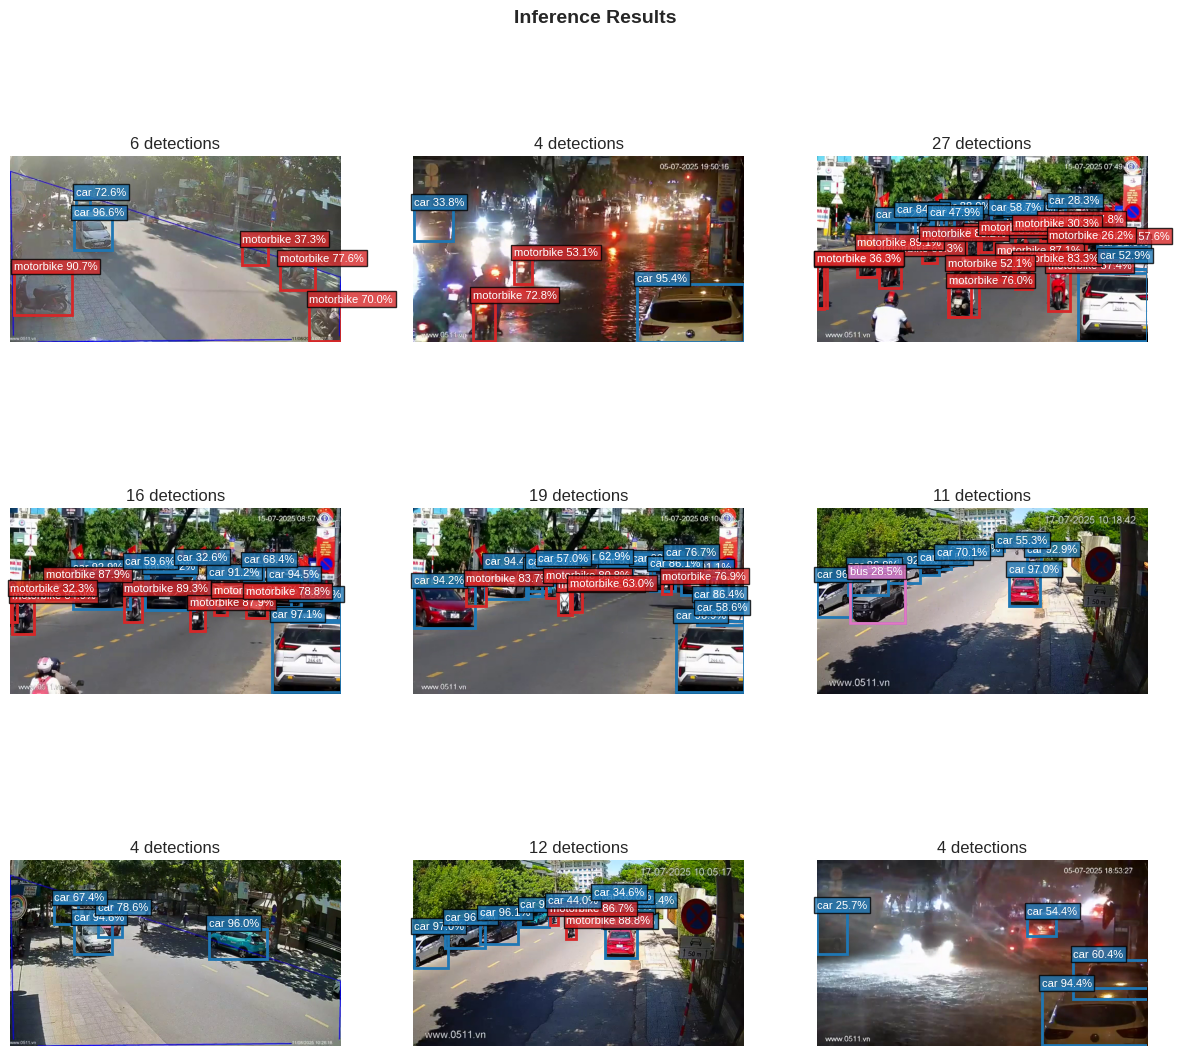

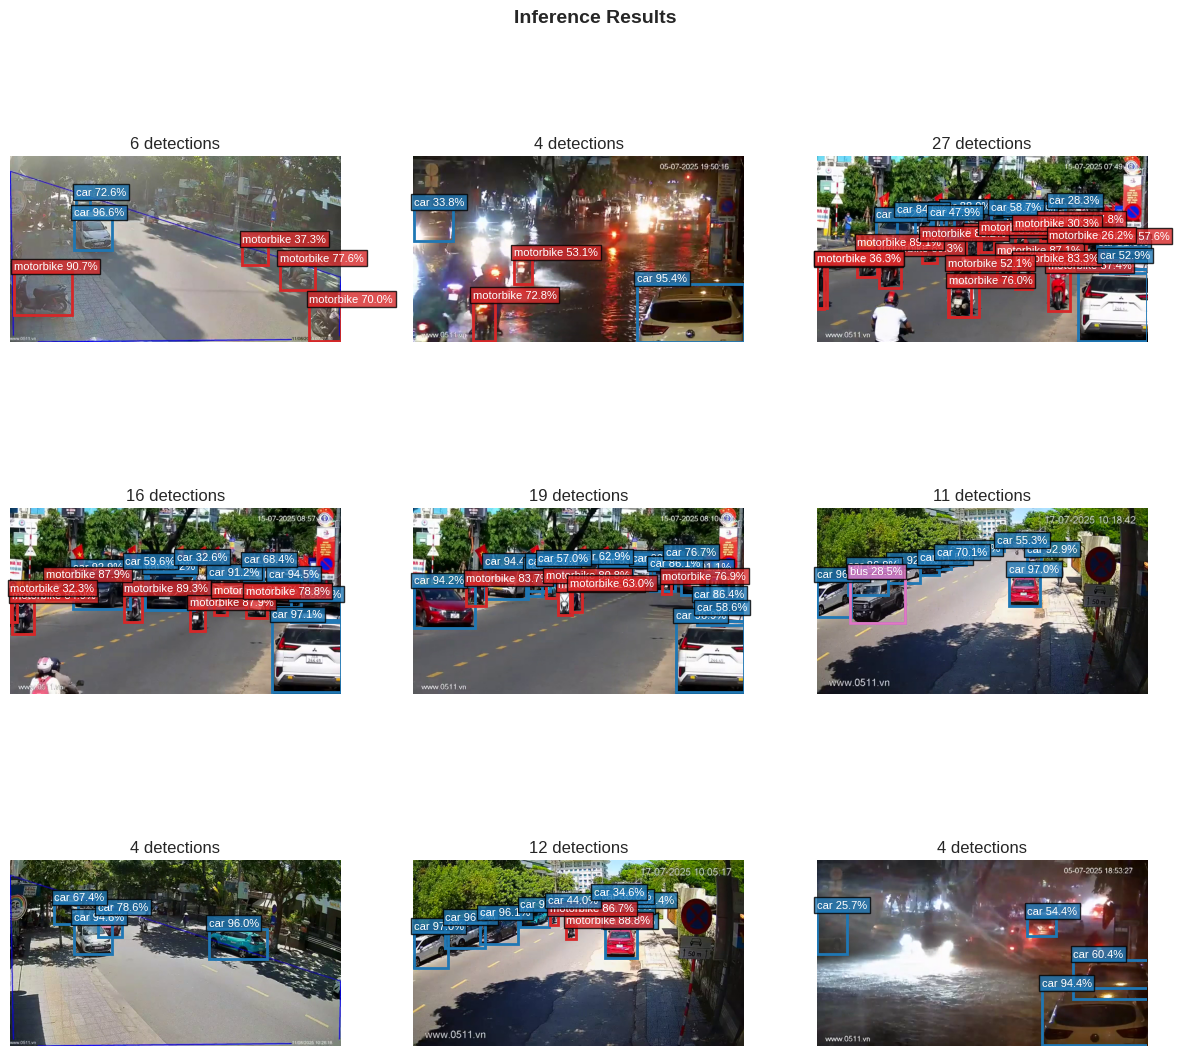

In [ ]:
# ==============================================================================
# CELL 13: Inference Results Grid
# ==============================================================================
def visualize_inference_grid(model_path: Path, image_dir: Path, class_names: dict, num_images: int = 9, output_path: str = None):
    """Render a grid of validation images with predicted bounding boxes."""
    image_paths = [path for path in image_dir.iterdir() if path.is_file()][:num_images]
    if not image_paths or not model_path.exists():
        print("[WARNING] Inference grid skipped: images or model weights are unavailable")
        return None

    model = YOLO(str(model_path))
    grid_size = int(np.ceil(np.sqrt(len(image_paths))))
    figure, axes = plt.subplots(grid_size, grid_size, figsize=(4 * grid_size, 4 * grid_size))
    axes = np.atleast_1d(axes).ravel()
    colors = plt.cm.tab10(np.linspace(0, 1, len(class_names)))

    for axis, image_path in zip(axes, image_paths):
        result = model.predict(str(image_path), conf=0.25, verbose=False)[0]
        image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
        axis.imshow(image)
        for box in result.boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
            class_index = int(box.cls)
            confidence = float(box.conf)
            color = colors[class_index % len(colors)]
            axis.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=2))
            label = f"{class_names.get(class_index, f'class_{class_index}')} {confidence:.1%}"
            axis.text(x1, max(y1 - 5, 0), label, fontsize=8, color="white", bbox={"facecolor": color, "alpha": 0.8, "pad": 2})
        axis.set_title(f"{len(result.boxes)} detections")
        axis.axis("off")

    for axis in axes[len(image_paths):]:
        axis.axis("off")
    figure.suptitle("Inference Results", fontsize=14, fontweight="bold")
    figure.tight_layout()
    if output_path:
        figure.savefig(output_path, bbox_inches="tight", dpi=150)
        print(f"[INFO] Inference grid saved to: {output_path}")
    plt.show()
    return figure


visualize_inference_grid(best_weights, val_images_dir, UNIFIED_CLASSES, output_path="inference_grid.png")
if test_metrics:
    visualize_inference_grid(best_weights, test_images_dir, UNIFIED_CLASSES, output_path="inference_grid_test.png")



In [ ]:
# ==============================================================================
# CELL 14: Final Summary Report
# ==============================================================================
def generate_summary_report(training_dir: Path, results_csv_path: Path, split_metrics: dict):
    """Print the best metrics, per-split per-class results and generated artifact locations."""
    best_weights_path = training_dir / "weights" / "best.pt"
    print("\n" + "=" * 70)
    print("TRAINING SUMMARY REPORT")
    print("=" * 70)
    if best_weights_path.exists():
        print(f"Model: {best_weights_path} ({best_weights_path.stat().st_size / 1024 ** 2:.2f} MB)")
    if results_csv_path.exists():
        dataframe = pd.read_csv(results_csv_path)
        dataframe.columns = dataframe.columns.str.strip()
        print(f"Training duration: {len(dataframe)} epochs")
        if "metrics/mAP50-95(B)" in dataframe.columns:
            best = dataframe.loc[dataframe["metrics/mAP50-95(B)"].idxmax()]
            print(f"Best epoch: {int(best.get('epoch', 0))}")
            for column in ["metrics/mAP50(B)", "metrics/mAP50-95(B)", "metrics/precision(B)", "metrics/recall(B)"]:
                if column in dataframe.columns:
                    print(f"  {column.split('/')[-1]}: {best[column]:.4f}")
    for split, result in split_metrics.items():
        if not result:
            continue
        print(f"Per-class results (best.pt on the {split} set):")
        print(f"  {'class':<12}{'precision':>10}{'recall':>10}{'mAP50':>10}{'mAP50-95':>10}")
        for name, values in {**result["per_class"], "all": result["overall"]}.items():
            print(f"  {name:<12}{values['precision']:>10.3f}{values['recall']:>10.3f}{values['mAP50']:>10.3f}{values['mAP50-95']:>10.3f}")
    print("Visualizations: dataset_distribution.png, training_curves.png, confusion_matrices.png, inference_grid.png")
    if split_metrics.get("test"):
        print("Test set files: test_metrics.csv, val_test_comparison.png, confusion_matrices_test.png, inference_grid_test.png")
    print("=" * 70)


generate_summary_report(model_dir, results_csv, {"val": val_metrics, "test": test_metrics})



TRAINING SUMMARY REPORT
Model: /kaggle/working/runs/train/vehicle_detection_v9/weights/best.pt (5.12 MB)
Training duration: 44 epochs
Best epoch: 39
  mAP50(B): 0.9021
  mAP50-95(B): 0.7856
  precision(B): 0.8768
  recall(B): 0.8333
Per-class results (best.pt on the validation set):
  class        precision    recall     mAP50  mAP50-95
  car              0.926     0.926     0.977     0.893
  motorbike        0.890     0.908     0.961     0.773
  bus              0.889     0.821     0.896     0.819
  truck            0.798     0.679     0.774     0.659
Visualizations: dataset_distribution.png, training_curves.png, confusion_matrices.png, inference_grid.png
